[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LotfiDjebbar/atelier-transformers/blob/main/Transformer_Encoder_Decoder.ipynb)

# 🤖 Transformers Encoder-Decoder — Pratique

**Atelier Deep Learning · Lotfi Djebbar & Issam Menas**

Ce notebook a deux parties :

1. **Partie 1 — L'application** : on construit un traducteur français → anglais avec un vrai modèle encoder-decoder, et on regarde à l'intérieur.
2. **Partie 2 — Transformer Grand Prix** 🏎️ : une course en direct où chacun pilote depuis son PC, avec le classement au projecteur.

👉 Exécutez les cellules dans l'ordre avec **Shift + Entrée**.

---
# Partie 1 — L'application : un traducteur encoder-decoder

### 0. Installation

On installe deux petites bibliothèques dont le tokenizer du modèle a besoin.

In [ ]:
!pip install -q transformers sentencepiece sacremoses

### 1. Charger le modèle

On utilise **MarianMT** (`Helsinki-NLP/opus-mt-fr-en`), un Transformer encoder-decoder entraîné uniquement pour traduire du français vers l'anglais.

- Le **tokenizer** découpe le texte en tokens et les transforme en nombres.
- Le **modèle** contient l'encoder et le decoder.
- `attn_implementation="eager"` demande au modèle de garder ses poids d'attention, pour qu'on puisse les afficher plus tard.
- `torch.set_grad_enabled(False)` : on ne fait pas d'entraînement, donc pas besoin de calculer de gradients.

In [ ]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

torch.set_grad_enabled(False)

nom_modele = "Helsinki-NLP/opus-mt-fr-en"
tokenizer = AutoTokenizer.from_pretrained(nom_modele)
model = AutoModelForSeq2SeqLM.from_pretrained(nom_modele, attn_implementation="eager")

### 2. Traduire en trois lignes

1. Le tokenizer transforme la phrase en IDs.
2. `generate` fait tout le travail : l'encoder lit la phrase, puis le decoder écrit la traduction token par token.
3. `decode` retransforme les IDs en texte.

In [ ]:
entree = tokenizer("Le chat dort", return_tensors="pt")
sortie = model.generate(**entree)
tokenizer.decode(sortie[0], skip_special_tokens=True)

'The Cat Sleeps'

### 3. Ouvrir la boîte

Le modèle a bien deux moitiés : un empilement de couches d'encoder et un empilement de couches de decoder.

On affiche ensuite **une couche du decoder**. On y retrouve les trois étages de la slide « Le decoder : trois étages » :

| Nom dans le code | Rôle |
|---|---|
| `self_attn` | Masked self-attention : relire ce qu'on a déjà écrit |
| `encoder_attn` | **Cross-attention** : consulter la phrase source (le pont !) |
| `fc1`, `fc2` | Feed-forward : digérer l'information |

In [ ]:
print("Couches de l'encoder :", len(model.model.encoder.layers))
print("Couches du decoder   :", len(model.model.decoder.layers))
model.model.decoder.layers[0]

Couches de l'encoder : 6
Couches du decoder   : 6


MarianDecoderLayer(
  (self_attn): MarianAttention(
    (k_proj): Linear(in_features=512, out_features=512, bias=True)
    (v_proj): Linear(in_features=512, out_features=512, bias=True)
    (q_proj): Linear(in_features=512, out_features=512, bias=True)
    (out_proj): Linear(in_features=512, out_features=512, bias=True)
  )
  (activation_fn): SiLU()
  (self_attn_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
  (encoder_attn): MarianAttention(
    (k_proj): Linear(in_features=512, out_features=512, bias=True)
    (v_proj): Linear(in_features=512, out_features=512, bias=True)
    (q_proj): Linear(in_features=512, out_features=512, bias=True)
    (out_proj): Linear(in_features=512, out_features=512, bias=True)
  )
  (encoder_attn_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc1): Linear(in_features=512, out_features=2048, bias=True)
  (fc2): Linear(in_features=2048, out_features=512, bias=True)
  (final_layer_norm): LayerN

### 4. Les tokens

Le modèle ne lit pas des mots mais des **tokens**.

- `▁` marque le début d'un mot.
- `</s>` est le token de fin de phrase.
- Chaque token correspond à un **ID**, un numéro dans le vocabulaire du modèle.

Les mots rares ou longs sont découpés en plusieurs morceaux.

In [ ]:
phrase = "Le chat dort sur le canapé"
ids = tokenizer(phrase).input_ids
print(tokenizer.convert_ids_to_tokens(ids))
print(ids)

['▁Le', '▁chat', '▁d', 'or', 't', '▁sur', '▁le', '▁canapé', '</s>']
[60, 9801, 20, 259, 75, 36, 19, 20936, 0]


In [ ]:
tokenizer.tokenize("incompréhensiblement")

['▁in', 'com', 'pré', 'hen', 'sible', 'ment']

### 5. L'encoder : la « mémoire »

On fait tourner **uniquement l'encoder** sur la phrase source.

Le résultat a la forme `[1, nombre de tokens, 512]` :
- 1 phrase,
- **un vecteur par token** (pas un seul vecteur pour toute la phrase),
- 512 nombres par vecteur.

C'est cette mémoire que le decoder ira consulter grâce à la cross-attention.

In [ ]:
entree = tokenizer("Le chat dort", return_tensors="pt")
memoire = model.get_encoder()(**entree).last_hidden_state
print(tokenizer.convert_ids_to_tokens(entree.input_ids[0]))
print(memoire.shape)

['▁Le', '▁chat', '▁d', 'or', 't', '</s>']
torch.Size([1, 6, 512])


### 6. Le decoder, token par token

On refait à la main ce que fait `generate`, comme sur les slides « Étape 1 → Étape 4 » :

1. L'encoder tourne **une seule fois**.
2. Le decoder démarre avec un token de départ.
3. À chaque étape, il donne une probabilité à chaque token du vocabulaire. On affiche les 3 meilleurs.
4. On garde le plus probable (**greedy**), on l'ajoute à ce qui est déjà écrit, et on relance le decoder.
5. On s'arrête quand le modèle écrit `</s>`.

La ligne avec `pad_token_id` interdit au modèle de choisir le token de remplissage, qui ne sert qu'à aligner les phrases.

Le nombre affiché tout à la fin est le **nombre de passages du decoder**.

In [ ]:
def decoder_pas_a_pas(phrase, afficher=True):
    entree = tokenizer(phrase, return_tensors="pt")
    memoire = model.get_encoder()(**entree)
    ecrit = torch.tensor([[model.config.decoder_start_token_id]])
    for etape in range(1, 60):
        logits = model(encoder_outputs=memoire, attention_mask=entree.attention_mask, decoder_input_ids=ecrit).logits[0, -1]
        logits[tokenizer.pad_token_id] = -float("inf")
        top = logits.softmax(-1).topk(3)
        if afficher:
            choix = "   ".join(f"{tokenizer.convert_ids_to_tokens(int(i))} {p:.0%}" for p, i in zip(top.values, top.indices))
            print(f"Étape {etape} :  {choix}")
        ecrit = torch.cat([ecrit, top.indices[:1].view(1, 1)], dim=1)
        if top.indices[0] == tokenizer.eos_token_id:
            break
    if afficher:
        print("\nTraduction :", tokenizer.decode(ecrit[0], skip_special_tokens=True))
    return etape


decoder_pas_a_pas("Le chat dort")

Étape 1 :  ▁The 57%   ▁Cat 12%   ▁♪ 2%
Étape 2 :  ▁cat 53%   ▁Cat 33%   ▁cats 1%
Étape 3 :  ▁sleep 45%   ▁is 20%   ' 14%
Étape 4 :  s 91%   </s> 0%   es 0%
Étape 5 :  </s> 71%   . 12%   , 1%

Traduction : The cat sleeps


5

### 7. La carte de cross-attention

Sur la slide « La cross-attention : le pont », les pourcentages étaient inventés. Ici, ce sont **les vrais**.

- **Une ligne** = le mot que le decoder est en train d'écrire.
- **Une colonne** = un mot de la phrase française (la mémoire de l'encoder).
- **Une case** = combien le decoder regarde ce mot français pour écrire ce mot anglais.

On fait la moyenne sur toutes les têtes et toutes les couches, et on retire la colonne `</s>` pour que la carte soit plus lisible.

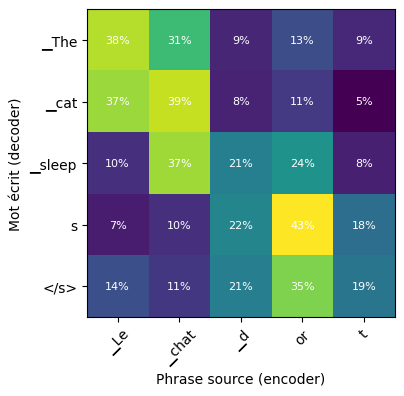

In [ ]:
def calculer_carte(phrase):
    entree = tokenizer(phrase, return_tensors="pt")
    traduction = model.generate(**entree, num_beams=1, do_sample=False)
    res = model(**entree, decoder_input_ids=traduction[:, :-1], output_attentions=True)
    carte = torch.stack(res.cross_attentions).mean(dim=(0, 2))[0, :, :-1]
    carte = carte / carte.sum(-1, keepdim=True)
    mots_source = tokenizer.convert_ids_to_tokens(entree.input_ids[0])[:-1]
    mots_traduits = tokenizer.convert_ids_to_tokens(traduction[0, 1:])
    return carte, mots_source, mots_traduits


def afficher_carte(phrase):
    carte, mots_source, mots_traduits = calculer_carte(phrase)
    plt.figure(figsize=(len(mots_source) + 2, len(mots_traduits) * 0.6 + 1))
    plt.imshow(carte, cmap="viridis")
    plt.xticks(range(len(mots_source)), mots_source, rotation=45)
    plt.yticks(range(len(mots_traduits)), mots_traduits)
    for i in range(len(mots_traduits)):
        for j in range(len(mots_source)):
            plt.text(j, i, f"{carte[i, j]:.0%}", ha="center", va="center", color="white", fontsize=8)
    plt.xlabel("Phrase source (encoder)")
    plt.ylabel("Mot écrit (decoder)")
    plt.show()


afficher_carte("Le chat dort")

Essayez une phrase où l'ordre des mots change entre le français et l'anglais : la diagonale se « croise ».

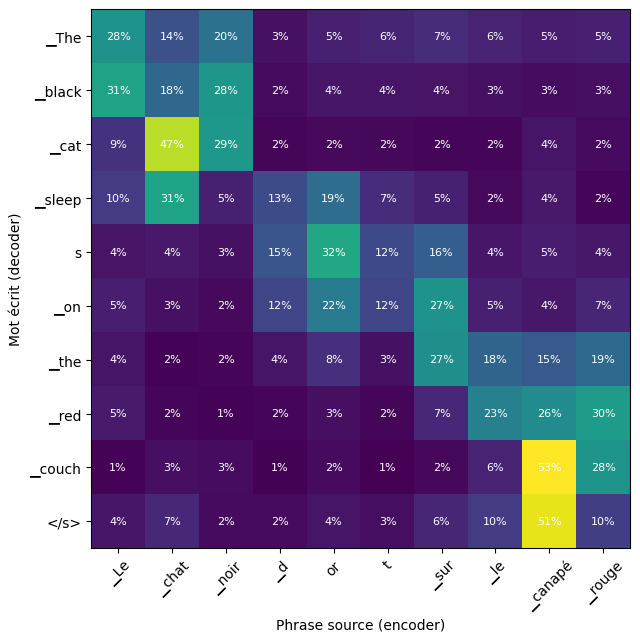

In [ ]:
afficher_carte("Le chat noir dort sur le canapé rouge")

### 8. Choisir le mot suivant : trois stratégies

La fonction `traduire` permet de choisir la stratégie de décodage :

| Stratégie | Paramètres | Idée |
|---|---|---|
| Greedy | `num_beams=1` | Toujours le mot le plus probable |
| Beam search | `num_beams=5` | On garde les 5 meilleures phrases en parallèle |
| Sampling | `do_sample=True`, `temperature` | On tire au hasard selon les probabilités |

Plus la **température** est haute, plus le modèle prend de risques. Relancez la cellule : le sampling change à chaque fois, pas les deux autres.

In [ ]:
def traduire(phrase, strategie="Beam search", temperature=1.0):
    entree = tokenizer(phrase, return_tensors="pt")
    if strategie == "Greedy":
        sortie = model.generate(**entree, num_beams=1, do_sample=False)
    elif strategie == "Beam search":
        sortie = model.generate(**entree, num_beams=5, do_sample=False)
    else:
        sortie = model.generate(**entree, num_beams=1, do_sample=True, temperature=temperature, top_k=0)
    return tokenizer.decode(sortie[0], skip_special_tokens=True)

In [ ]:
phrase = "Il pleut des cordes depuis ce matin."
print("Greedy        :", traduire(phrase, "Greedy"))
print("Beam search   :", traduire(phrase, "Beam search"))
for t in [0.5, 1.0, 1.5]:
    print(f"Sampling T={t} :", traduire(phrase, "Sampling", t))

Greedy        : It's been raining ropes since this morning.
Beam search   : It's been raining ropes since this morning.
Sampling T=0.5 : It's been raining strings since this morning.
Sampling T=1.0 : It' pillars all before this morning
Sampling T=1.5 : 尺 lyrics COUNCIL钾 MOU withoutincarcération industriel Then轴 1874 fired pitchedme injured organise bribery


### 9. L'application 🚀

On assemble tout dans une petite interface :
- une zone de texte pour la phrase française,
- le choix de la stratégie et de la température,
- une option pour afficher la carte de cross-attention.

In [ ]:
import ipywidgets as widgets
from IPython.display import display

texte = widgets.Textarea(value="Le chat dort sur le canapé.", layout=widgets.Layout(width="100%", height="80px"))
strategie = widgets.Dropdown(options=["Greedy", "Beam search", "Sampling"], value="Beam search", description="Stratégie")
temperature = widgets.FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description="Température")
voir_carte = widgets.Checkbox(value=False, description="Afficher la carte d'attention")
bouton = widgets.Button(description="Traduire", button_style="success", icon="language")
resultat = widgets.Output()


def au_clic(_):
    with resultat:
        resultat.clear_output()
        print("🇬🇧", traduire(texte.value, strategie.value, temperature.value))
        if voir_carte.value:
            afficher_carte(texte.value)


bouton.on_click(au_clic)
display(widgets.VBox([texte, strategie, temperature, voir_carte, bouton, resultat]))

---
# Partie 2 — 🏎️ Transformer Grand Prix

Place à la course ! Votre moteur : le Transformer encoder-decoder que vous venez d'explorer.

1. Ouvrez le **lien affiché au tableau** (ou scannez le QR code) dans votre navigateur.
2. Choisissez un nom de pilote et une couleur : votre voiture apparaît sur la grille.
3. Au départ des feux rouges, bouclez les **6 secteurs**. Chaque secteur porte sur une notion de la Partie 1, et le **garage** de chaque secteur fait tourner le vrai modèle pour vous.

| Règle | Effet |
|---|---|
| Mauvaise réponse | +15 s |
| Arrêt au stand (indice) | +30 s |
| Premier à boucler un secteur | Secteur violet au tableau 🟣 |
| Classement | Le plus de secteurs, puis le meilleur temps |

Vous pouvez aussi utiliser les cellules de la Partie 1 pour vérifier vos réponses. Bonne course ! 🏁